# A script to test full functionality of the counting function

In [1]:
import numpy as np
import pandas as pd
from tqdm import tqdm
import demes
import msprime
import os
import sys
sys.path.append("../src/")
import seaborn as sns
import matplotlib.pyplot as plt
from pathos.multiprocessing import ProcessingPool as Pool
import plotly.io as pio

from CountCoalEvents import CountCoalEvents
from LatentSpaceEmbeddings import LatentSpaceEmbeddings
from PlotEmbeddings import PlotEmbeddings

def sim_contigs(deme_file_path, ts_dir, num_contigs=500, contig_length=5e6, num_replicates=1, recomb_rate = 1e-8, n=50, parallel=True):
    graph = demes.load(deme_file_path)
    demography = msprime.Demography.from_demes(graph)
    
    samples = {}
    for pop in demography.populations:
        if pop.default_sampling_time == 0:
            samples[pop.name] = n

    def simulate_replicate(i):
        ts = msprime.sim_ancestry(
            samples=samples,
            demography=demography,
            sequence_length=contig_length,
            recombination_rate=recomb_rate,
            random_seed=42+i
        )
        return i, ts
    if parallel:
        with Pool(os.cpu_count()) as pool:
            for i, ts in tqdm(pool.imap(simulate_replicate, range(num_contigs*num_replicates)), total=num_contigs*num_replicates):
                if num_replicates == 1:
                    ts.dump(f"{ts_dir}/contig_{i}.trees")
                else:
                    rep = i // num_contigs
                    contig = i % num_contigs
                    ts.dump(f"{ts_dir}/contig_{contig}_{rep}.trees")
    else:
        for i in tqdm(range(num_contigs*num_replicates)):
            _, ts = simulate_replicate(i)
            if num_replicates == 1:
                ts.dump(f"{ts_dir}/contig_{i}.trees")
            else:
                rep = i // num_contigs
                contig = i % num_contigs
                ts.dump(f"{ts_dir}/contig_{contig}_{rep}.trees")

def parse_counts_df(counts_df, delta):
    num_idx = counts_df["sample_2_idx"].max()+1
    num_time_points = counts_df["time_idx"].nunique()
    N = np.zeros((num_idx, num_idx, num_time_points), dtype=float)
    L = np.zeros((num_idx, num_idx, num_time_points), dtype=float)
    for row in counts_df.itertuples():
        # R[row.sample_1_idx, row.sample_2_idx, row.time_idx] = row.coal_rate
        N[row.sample_1_idx, row.sample_2_idx, row.time_idx] = row.num_coal_events
        L[row.sample_1_idx, row.sample_2_idx, row.time_idx] = row.num_uncoalesced
    
    # R += R.transpose((1,0,2))
    N += N.transpose((1,0,2))
    L += L.transpose((1,0,2))
    # R = (N+1)/(delta*(L+1))
    R = N/(delta*L)
    return N,L,R

def analysis_plot(R, time_points, K):
    n_per_pop = int(R.shape[0] / K)
    fig, axs = plt.subplots(1,2,figsize = (12,6), dpi = 500)
    sns.heatmap(R[:,:,0], ax=axs[0], vmin = 0, vmax = 2*np.nanmean(R))
    axs[0].set_title("R at time point 0")
    for pop1 in range(K):
        for pop2 in range(K):
            R_slice = R[pop1*n_per_pop:(pop1+1)*n_per_pop, pop2*n_per_pop:(pop2+1)*n_per_pop, :]
            if pop1 == pop2:
                mean_R = np.nanmean(R_slice, axis = (0,1))
                axs[1].plot(time_points, mean_R, label=f"Pop {pop1+1}")
            if pop1 < pop2:
                mean_R = np.mean(R_slice, axis=(0,1))
                axs[1].plot(time_points, mean_R, label=f"Pop {pop1+1} - Pop {pop2+1}")
    axs[1].set_title("Mean R through time")
    axs[1].legend()

    return fig


### 1. Simulating contigs and counting coalescent events

We simulate $500$ independent contigs of size $5$ Mb each to approximate a whole genome

In [31]:
ts_dir = "sim_data/"
# deme_file_path = "../data/deme_files/main_deme_files/split.yaml"
deme_file_path = "../data/deme_files/stdpopsim_deme_files/OutOfAfrica_4J17.yaml"
os.makedirs(ts_dir, exist_ok=True)
sim_contigs(deme_file_path=deme_file_path, ts_dir=ts_dir, num_contigs=20, contig_length=5e6, num_replicates=1, recomb_rate=1e-8, n=20, parallel=True)

100%|██████████| 20/20 [00:00<00:00, 51.51it/s]


We counts coalescent events to compute coalescent rates over time

/var/folders/r7/bmbjyrls5rg24ycmhm0lgjd40000gp/T/ipykernel_74328/4169993569.py:69: RuntimeWarning: invalid value encountered in divide
  R = N/(delta*L)


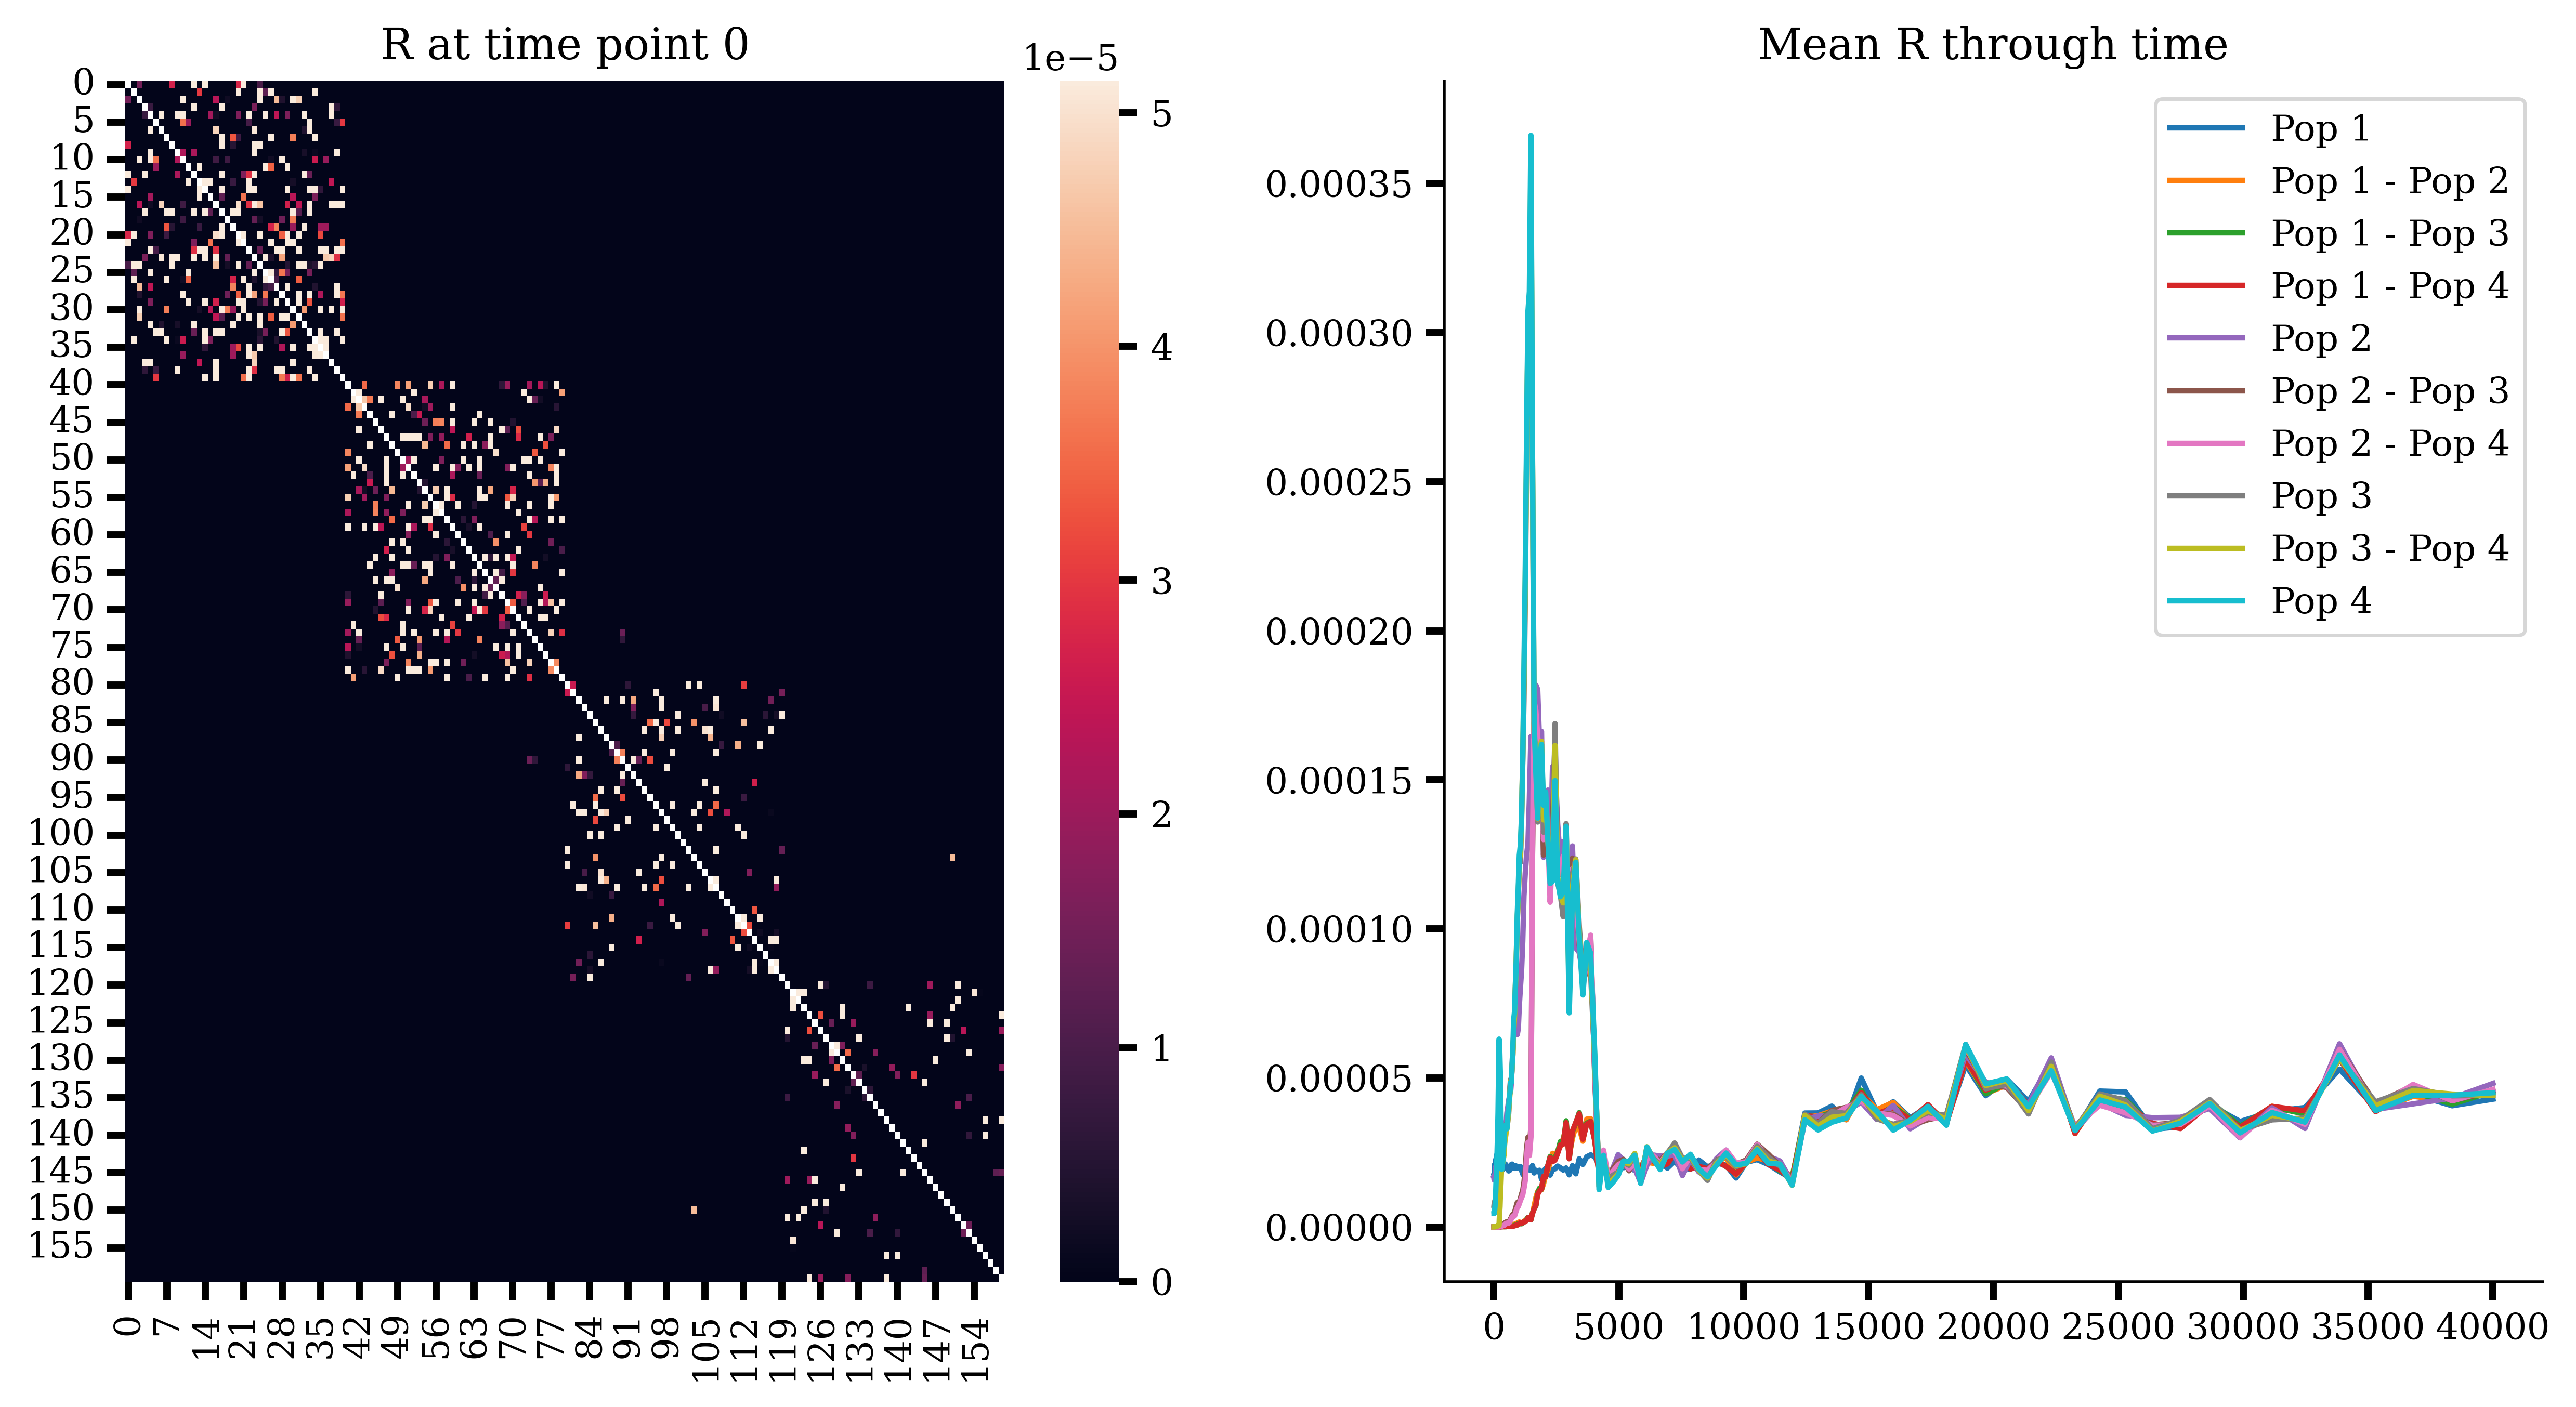

In [32]:
time_points = np.linspace(0,20000,100)
delta = 100
time_points = np.logspace(1,np.log10(40000),200)
window_sizes = np.array([delta]*200)
ts_dir = "sim_data/"
output_dir = "./counts_data/"
os.makedirs(output_dir, exist_ok=True)

CCE = CountCoalEvents(output_dir=output_dir, ts_dir=ts_dir, time_points=time_points, window_sizes=window_sizes)
CCE.count_coal_events_total(num_threads=os.cpu_count())
total_counts_df = CCE.aggregate_counts()

N,L,R = parse_counts_df(total_counts_df,delta)
fig = analysis_plot(R, time_points, K=4)

In [51]:
def count(ts,times,delta):
    n = ts.num_samples
    N = np.zeros((n, n, len(times)), dtype=int)
    L = np.zeros((n, n, len(times)), dtype=int)
    times_upper = times + delta
    pairs = np.column_stack(np.triu_indices(n, k=1))
    pairs = [tuple(pair) for pair in pairs]
    for i,j in tqdm(pairs):
            ts_simple = ts.simplify(samples=[i,j])
            coal_times = ts_simple.nodes_time[2:]
            left = np.searchsorted(coal_times,times,side='left')
            right = np.searchsorted(coal_times,times_upper,side='right')
            N[i,j,:] = right-left
            L[i,j,:] = len(coal_times)-left
    N += N.transpose((1,0,2))
    L += L.transpose((1,0,2))
    return N,L


In [59]:
ts

In [78]:
import tskit
delta=500
n=160
N = np.zeros((n, n, len(time_points)), dtype=int)
L = np.zeros((n, n, len(time_points)), dtype=int)
for i in range(10):
    ts = tskit.load(f"sim_data/contig_{i}.trees")
    N_sub,L_sub = count(ts,time_points,delta)
    N += N_sub
    L += L_sub

100%|██████████| 12720/12720 [00:27<00:00, 463.15it/s]


In [92]:
R = N/(delta*L)

/var/folders/r7/bmbjyrls5rg24ycmhm0lgjd40000gp/T/ipykernel_74328/3552839495.py:1: RuntimeWarning:

invalid value encountered in divide



<Axes: >

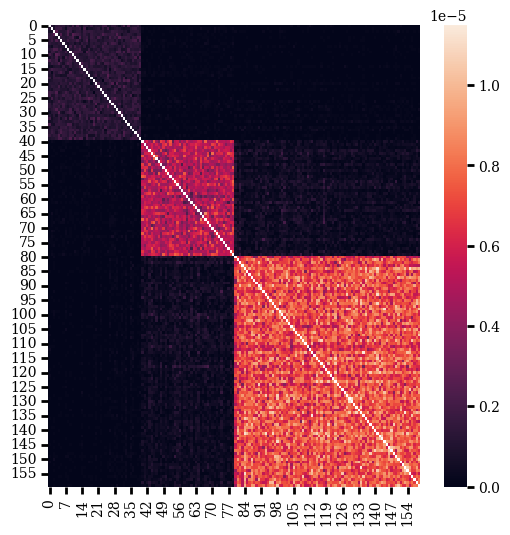

In [100]:
sns.heatmap(R[:,:,100])

### 2. Computing latent space embeddings

#### 2.1 by sample

In [86]:
# output_dir = "./counts_data/"
# total_counts_df = pd.read_parquet(os.path.join(output_dir, "total_counts.parquet"))
# R = df_to_rates(total_counts_df)
# R += 1e-6 # Draws the clusters a bit closer together
LSE_split = LatentSpaceEmbeddings(R=R, time_points=time_points)

embeddings = LSE_split.compute_embeddings_through_time(X_init=np.random.rand(R.shape[0], 2))
embeddings_df = LSE_split.create_embeddings_df()
embeddings_df.to_parquet(os.path.join(output_dir, "embeddings.parquet"), index=False)

100%|██████████| 200/200 [00:12<00:00, 15.53it/s]


In [88]:
output_dir = "./counts_data/"
embeddings_df = pd.read_parquet(os.path.join(output_dir, "embeddings.parquet"))
idx_to_sample_df = pd.read_parquet(os.path.join(output_dir, "idx_to_sample.parquet"))
# population_sample_dict = {"A": np.arange(100), "B": np.arange(100,200)}
population_sample_dict = {"YRI": np.arange(40), "CEU": np.arange(40,80), "CHB": np.arange(80,120), "JPT": np.arange(120,160)}
# population_sample_dict = {"Main": np.arange(100)}
sample_to_pop_df = pd.DataFrame([(sample_id, pop) for pop, sample_ids in population_sample_dict.items() for sample_id in sample_ids], columns=["sample_id", "population"])
plotter = PlotEmbeddings(embeddings_df=embeddings_df, sample_to_pop_df=sample_to_pop_df, idx_to_sample_df=idx_to_sample_df)
fig = plotter.dynamic_plot(log_time=True)
pio.write_html(fig, file=os.path.join(output_dir,"dynamic_3d_plot.html"))

In [89]:
fig

#### 2.2 by individual

In [6]:
time_points = np.linspace(0,20000,100)
output_dir = "./counts_data/"
total_counts_df = pd.read_parquet(os.path.join(output_dir, "total_counts.parquet"))
R = df_to_rates(total_counts_df)
R += 1e-6 # Draws the clusters a bit closer together
LSE_split = LatentSpaceEmbeddings(R=R, time_points=time_points, individuals=True)

embeddings = LSE_split.compute_embeddings_through_time()
embeddings_df = LSE_split.create_embeddings_df()
embeddings_df.to_parquet(os.path.join(output_dir, "embeddings.parquet"), index=False)

100%|██████████| 100/100 [00:00<00:00, 138.54it/s]


In [8]:
output_dir = "./counts_data/"
embeddings_df = pd.read_parquet(os.path.join(output_dir, "embeddings.parquet"))
idx_to_sample_df = pd.read_parquet(os.path.join(output_dir, "idx_to_sample.parquet"))
population_sample_dict = {"A": np.arange(20), "B": np.arange(20,40)}
sample_to_pop_df = pd.DataFrame([(sample_id, pop) for pop, sample_ids in population_sample_dict.items() for sample_id in sample_ids], columns=["sample_id", "population"])
plotter = PlotEmbeddings(embeddings_df=embeddings_df, sample_to_pop_df=sample_to_pop_df, idx_to_sample_df=idx_to_sample_df)
plotter.dynamic_plot()

### 3. using a subset of samples

100%|██████████| 500/500 [00:06<00:00, 82.70it/s]
/var/folders/r7/bmbjyrls5rg24ycmhm0lgjd40000gp/T/ipykernel_81209/960620713.py:13: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



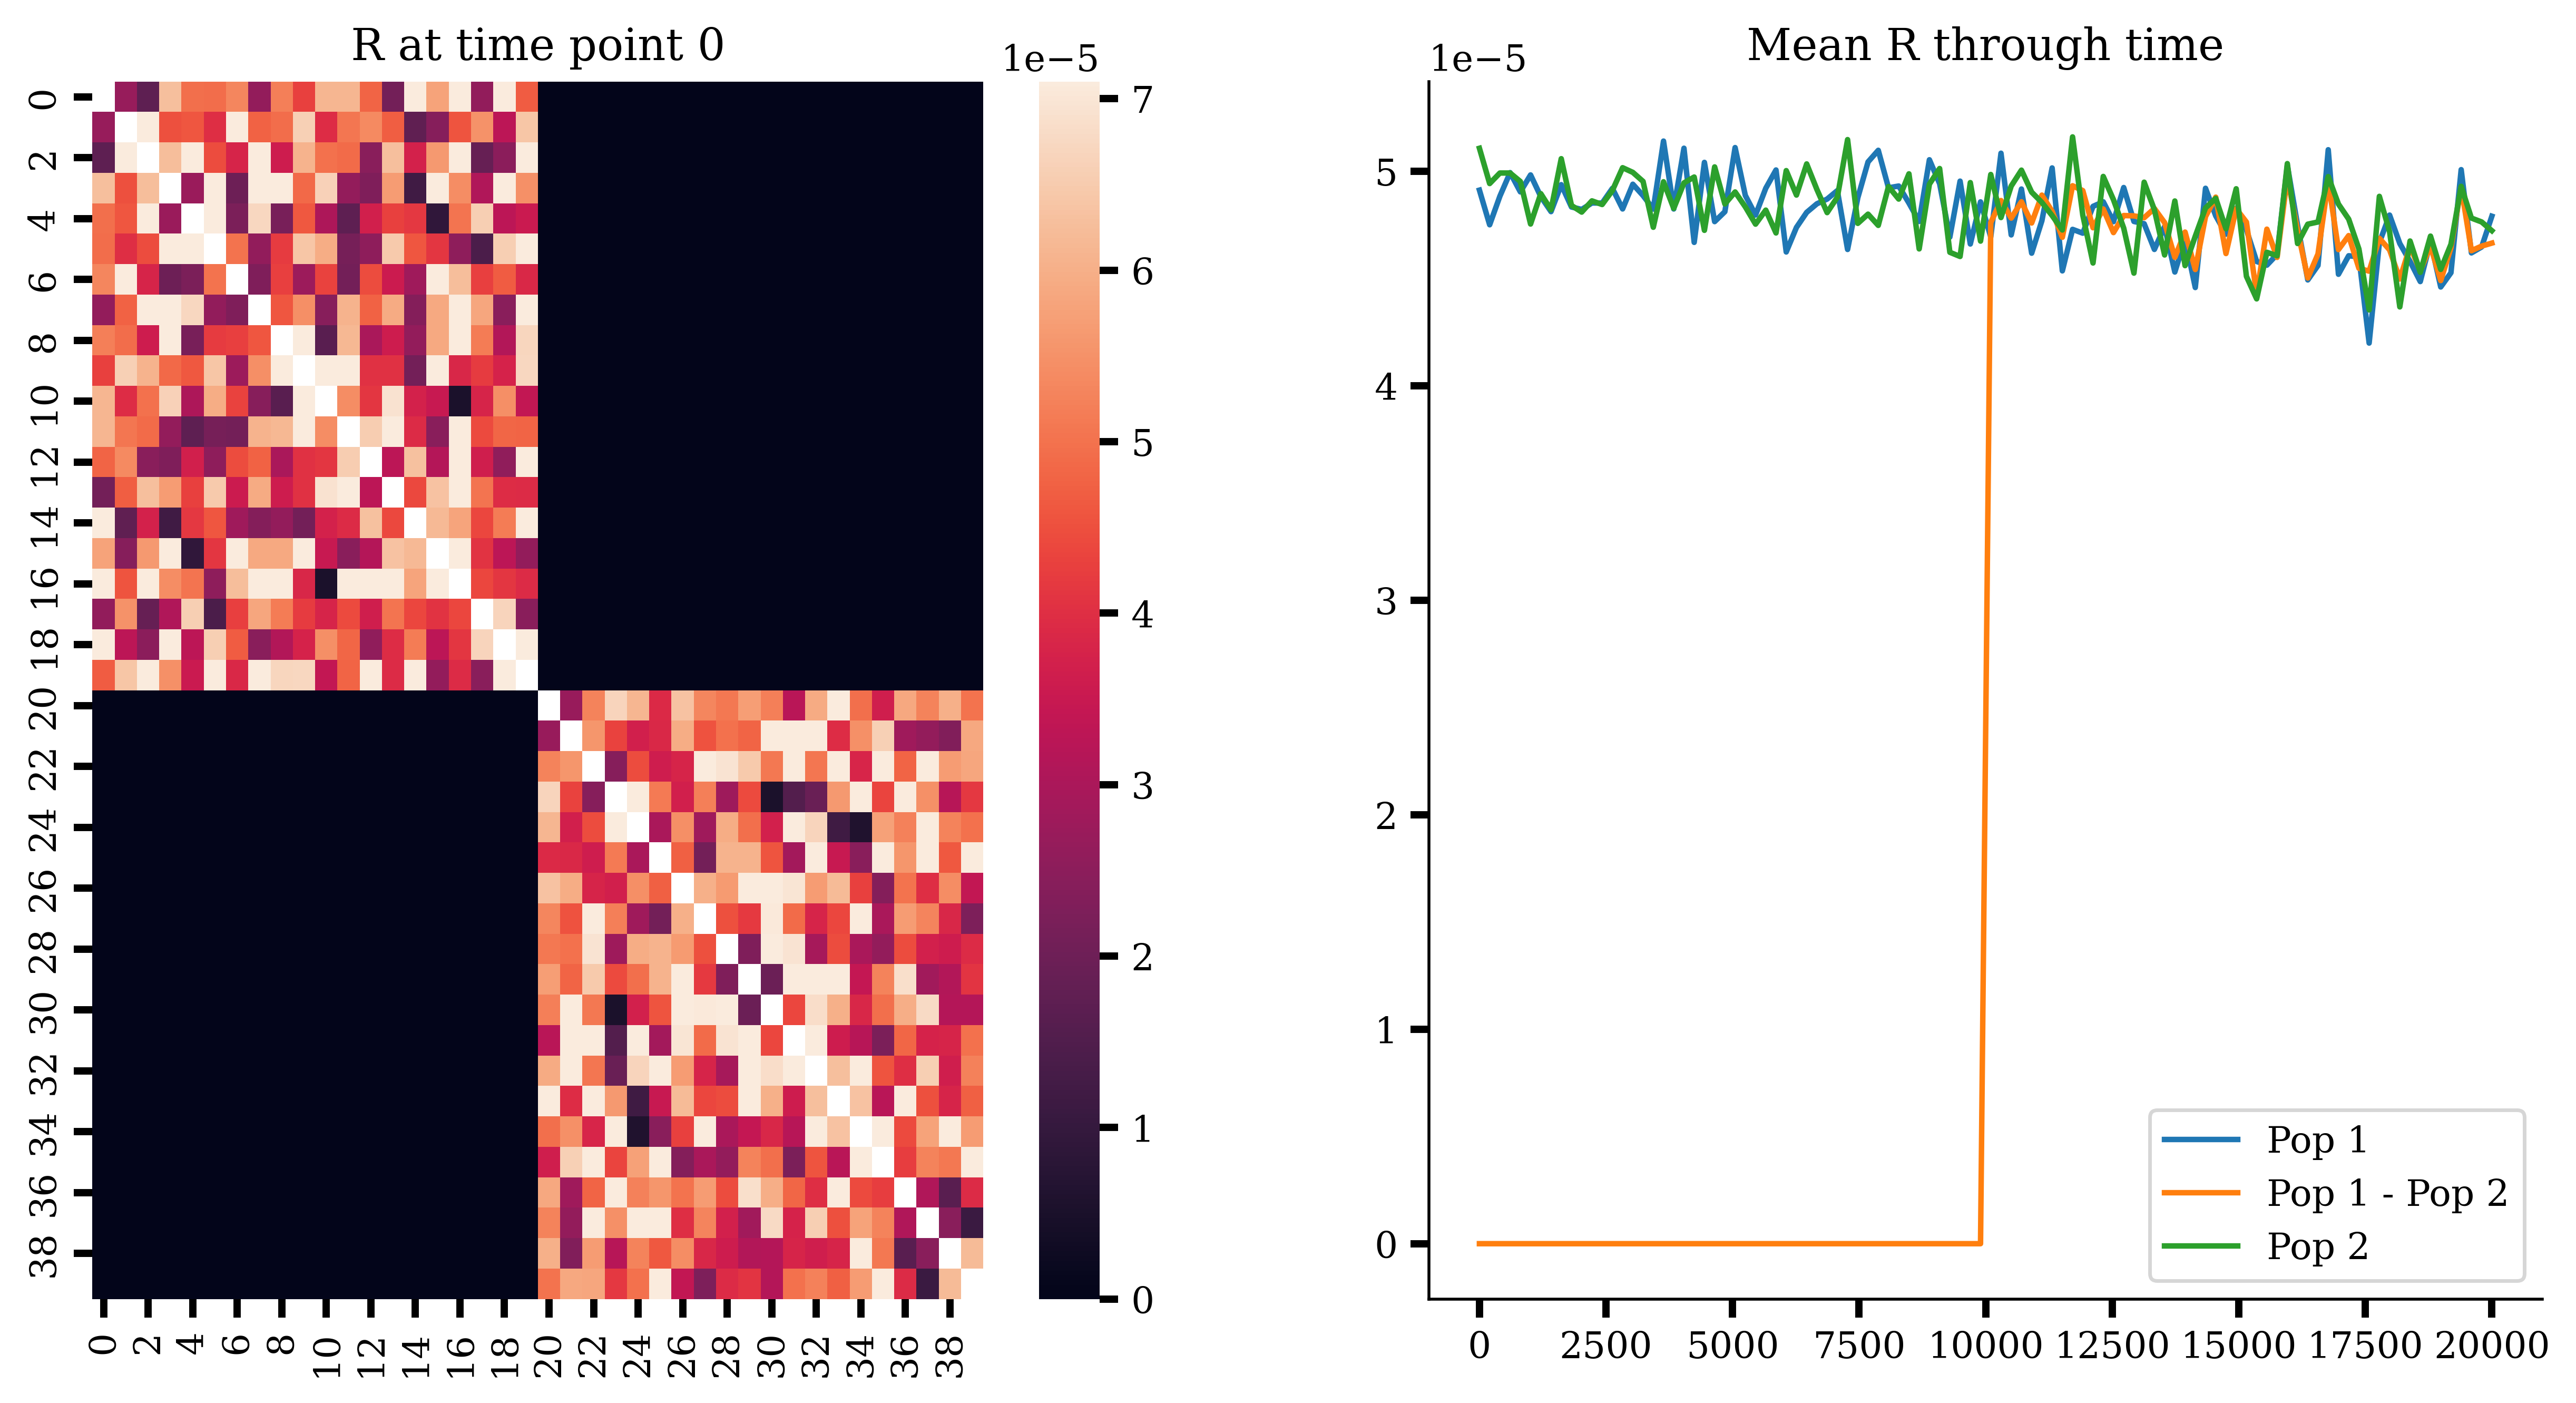

In [9]:
time_points = np.linspace(0,20000,100)
window_sizes = np.array([100]*100)
sample_ids = np.concatenate((np.arange(20),np.arange(40,60)))
ts_dir = "sim_data/"
output_dir = "./counts_data_subsamples/"
os.makedirs(output_dir, exist_ok=True)

CCE = CountCoalEvents(output_dir=output_dir, ts_dir=ts_dir, time_points=time_points, window_sizes=window_sizes, sample_ids=sample_ids)
_ = CCE.count_coal_events_total()
total_counts_df = CCE.aggregate_counts()
R = df_to_rates(total_counts_df)
fig = analysis_plot(R, time_points, K=2)
fig.show()

### 4. Contigs representing a posterior samples of an ARG

We simulate $100$ independent contigs of size $5$ Mb each to approximate a whole genome, and each contig is given 5 replicates to resemble posterior samples

In [10]:
ts_dir = "sim_data_replicates/"
deme_file_path = "../data/main_deme_files/split.yaml"
os.makedirs(ts_dir, exist_ok=True)
sim_contigs(deme_file_path=deme_file_path, ts_dir=ts_dir, num_contigs=100, contig_length=5e6, num_replicates=5, recomb_rate=1e-8, n=20)

100%|██████████| 500/500 [00:06<00:00, 83.11it/s]


100%|██████████| 500/500 [00:14<00:00, 35.21it/s]
/var/folders/r7/bmbjyrls5rg24ycmhm0lgjd40000gp/T/ipykernel_81209/2387430660.py:12: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



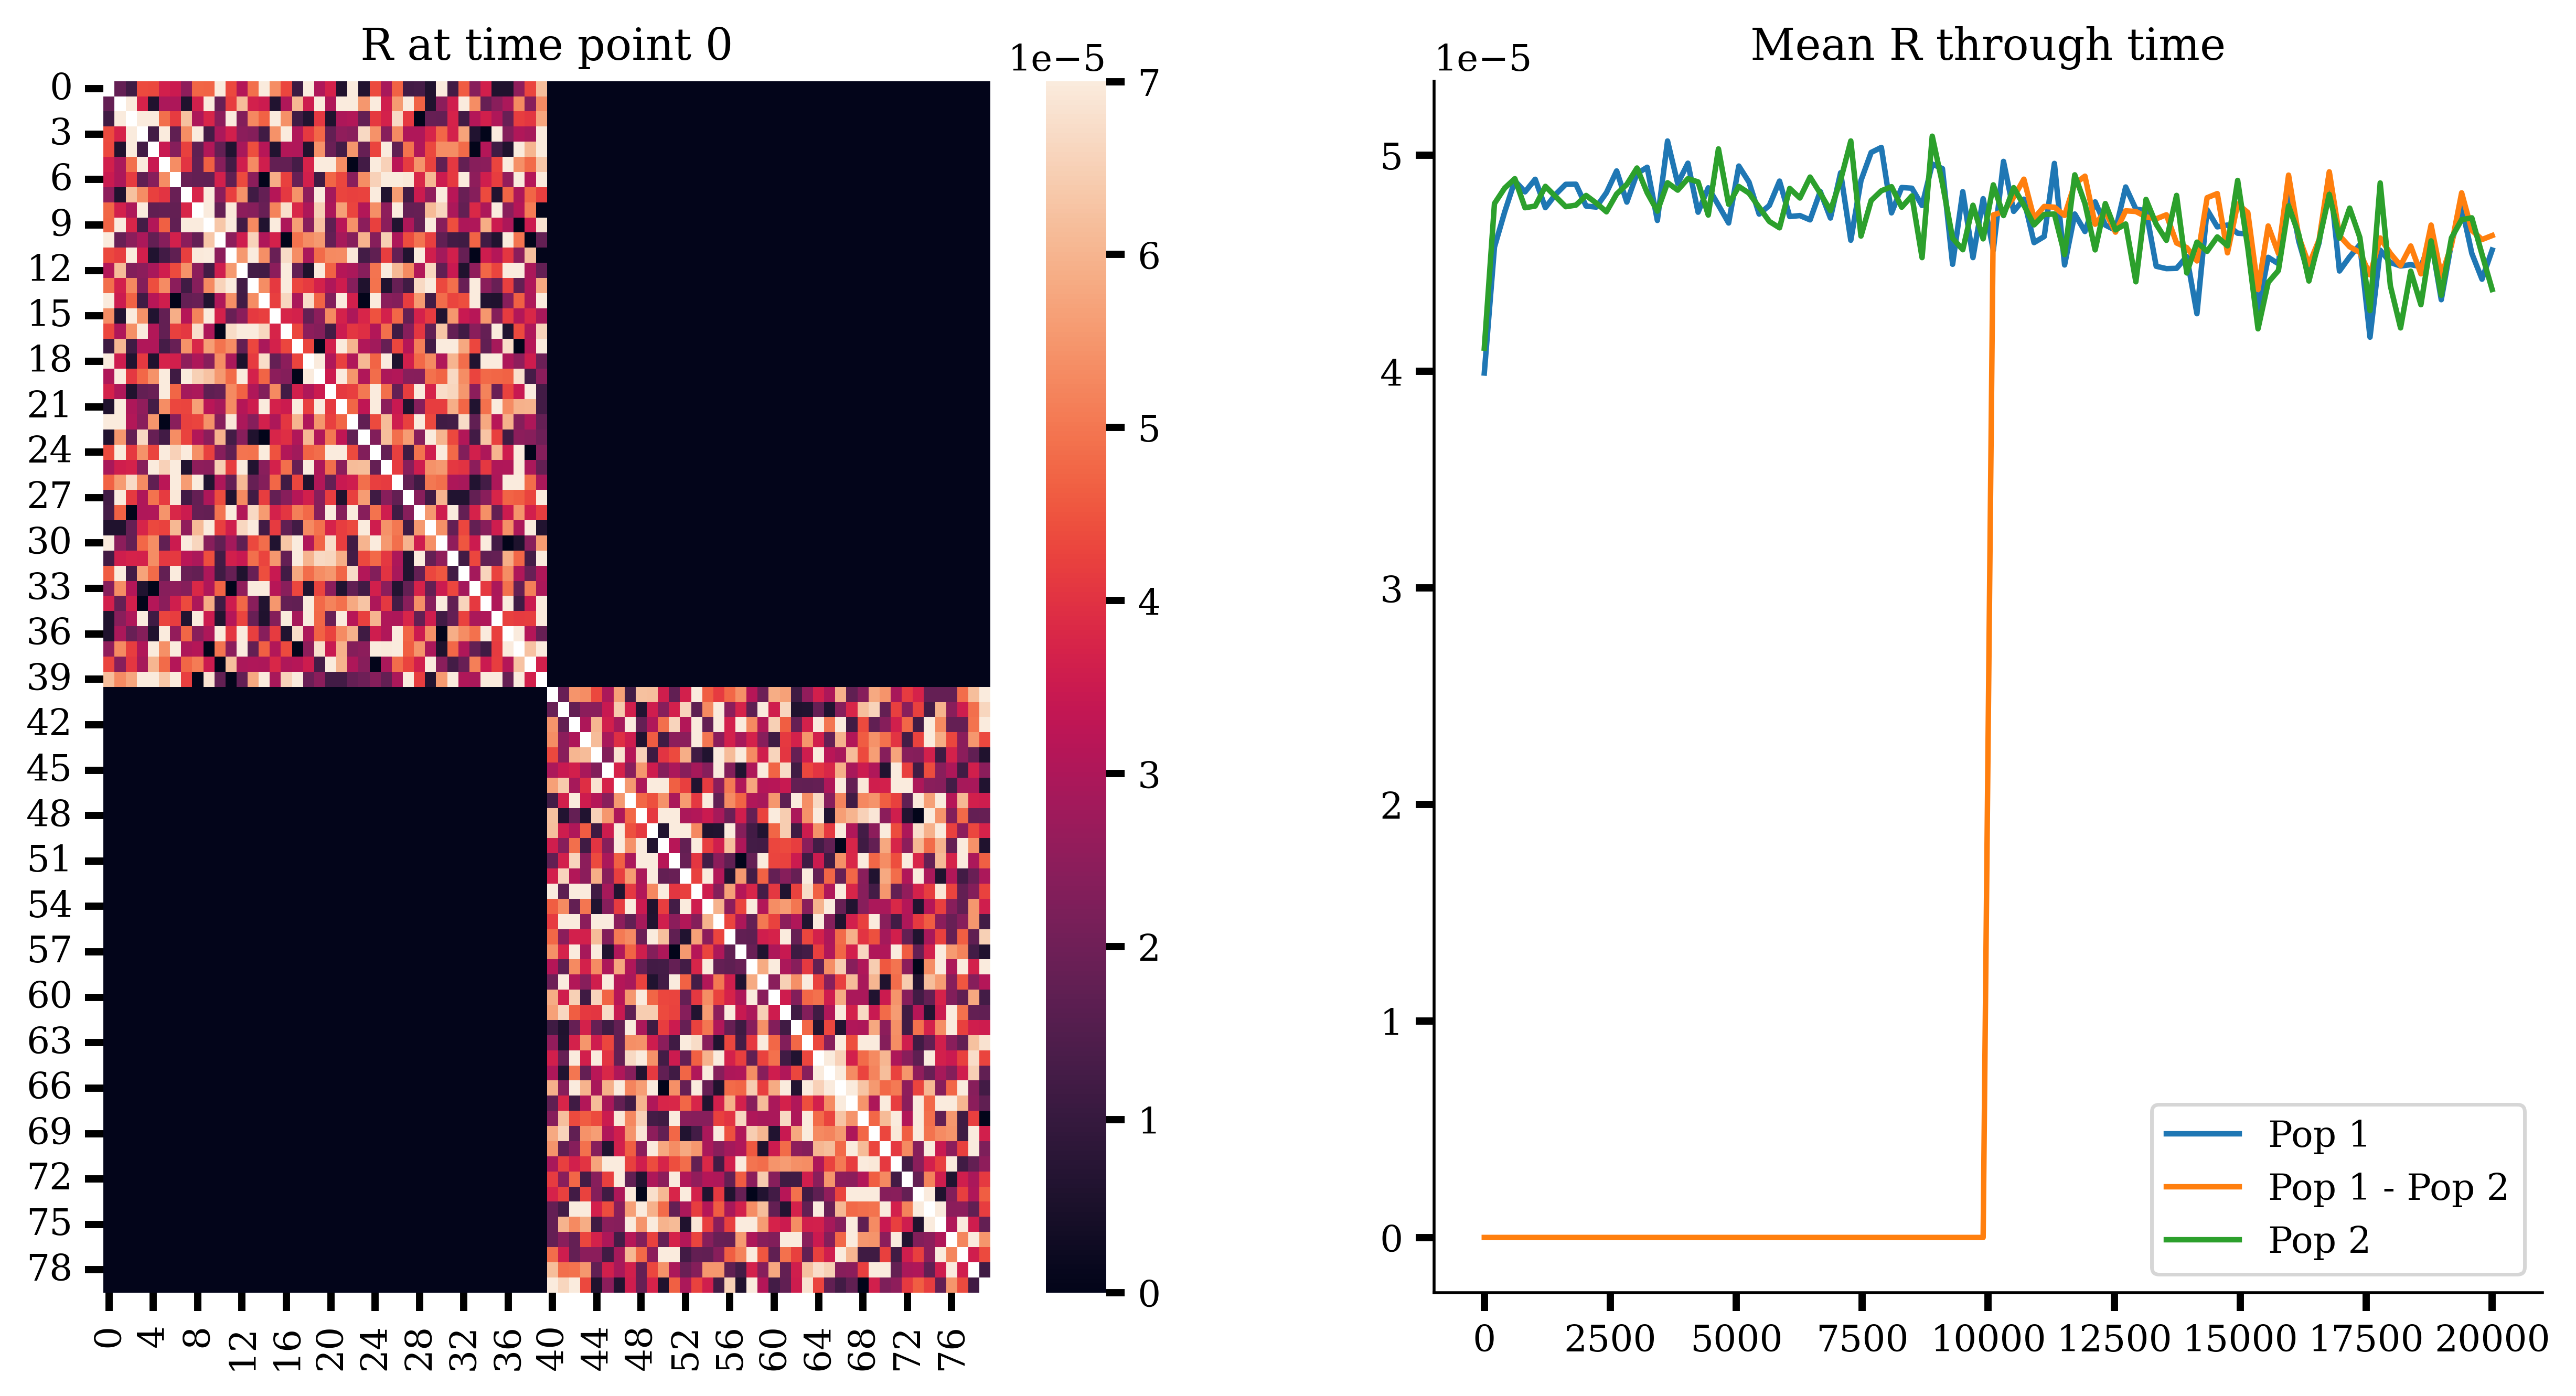

In [11]:
time_points = np.linspace(0,20000,100)
window_sizes = np.array([100]*100)
ts_dir = "sim_data_replicates/"
output_dir = "./counts_data_replicates/"
os.makedirs(output_dir, exist_ok=True)

CCE = CountCoalEvents(output_dir=output_dir, ts_dir=ts_dir, time_points=time_points, window_sizes=window_sizes, num_posterior_samples=5)
_ = CCE.count_coal_events_total()
total_counts_df = CCE.aggregate_counts()
R = df_to_rates(total_counts_df)
fig = analysis_plot(R, time_points, K=2)
fig.show()